# 11. Input Representation Experiments: Log Transform and Feature Subsets

CSCI323 Modern AI — Group FT13 (owner: Ian)

This notebook supplements `Red_White_Wine_Quality_Modelling_Comparisons.ipynb`. It uses **the same data cleaning, the same 80/20 stratified split (random_state = 42) and the four selected model configurations from Section 9**, so every number here is directly comparable with the main notebook.

The models stay fixed. Only the **inputs** change.

**Questions investigated**
1. Several chemical features are strongly right-skewed (a few wines with very large values). Does a log transform of those features improve any of the four models?
2. Section 8.4 showed that Random Forest loses little accuracy when given only the most informative features. Does that hold for Linear Regression, KNN and MLP too, or is it specific to RF?

**Method**
- Four selected models: Linear Regression, tuned Random Forest (Section 8.2), tuned KNN (Section 8.6), tuned MLP (Section 8.1). Hyperparameters are copied, not re-tuned.
- Every variant is fitted on the training set and scored once on the test set (MAE, RMSE, R²). Five-fold training-set CV MAE (same `KFold` as the main notebook) is reported alongside, to show the test differences are not just split noise.
- Any preprocessing (skewness rule, feature ranking) is decided on the **training set only**.

## 11.1 Setup: same data, split and selected models as Sections 1–2 and 9

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Same source as the main notebook (falls back to local copies in ./data if present)
base_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
def load(name):
    local = Path("data") / f"winequality-{name}.csv"
    return pd.read_csv(local if local.exists() else base_url + f"winequality-{name}.csv", sep=";")

df = load("red"); white_df = load("white")

# Remove exact duplicate rows before splitting (Section 1)
df_clean = df.drop_duplicates().copy()
white_df_clean = white_df.drop_duplicates().copy()

X = df_clean.drop(columns=["quality"]); y = df_clean["quality"]
white_X = white_df_clean.drop(columns=["quality"]); white_y = white_df_clean["quality"]

# Same 80/20 stratified split as Section 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
white_X_train, white_X_test, white_y_train, white_y_test = train_test_split(
    white_X, white_y, test_size=0.2, random_state=42, stratify=white_y)

# Same 5-fold CV object as the main notebook
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Red:   train", X_train.shape, "| test", X_test.shape)
print("White: train", white_X_train.shape, "| test", white_X_test.shape)

Red:   train (1087, 11) | test (272, 11)
White: train (3168, 11) | test (793, 11)


In [2]:
# The four selected configurations from Section 9 (hyperparameters copied from Sections 8.1, 8.2, 8.6)
def make_models(wine):
    rf_params = ({"n_estimators": 200, "max_depth": None, "min_samples_leaf": 3} if wine == "Red"
                 else {"n_estimators": 200, "max_depth": 20, "min_samples_leaf": 3})
    knn_k = 11 if wine == "Red" else 15
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(**rf_params, random_state=42, n_jobs=-1),
        "KNN": Pipeline([("scaler", StandardScaler()),
                         ("knn", KNeighborsRegressor(n_neighbors=knn_k, weights="distance", p=1))]),
        "MLP": Pipeline([("scaler", StandardScaler()),
                         ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                              alpha=0.001, learning_rate_init=0.001, max_iter=2000,
                                              early_stopping=True, validation_fraction=0.15,
                                              n_iter_no_change=30, random_state=42))]),
    }

MODEL_ORDER = ["Linear Regression", "Random Forest", "KNN", "MLP"]
DATASETS = {"Red":   (X_train, X_test, y_train, y_test),
            "White": (white_X_train, white_X_test, white_y_train, white_y_test)}

def evaluate(model, X_tr, y_tr, X_te, y_te):
    """Fit on the training set, score once on the test set; also 5-fold CV MAE on the training set."""
    cv_mae = -cross_val_score(model, X_tr, y_tr, cv=cv, scoring="neg_mean_absolute_error").mean()
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {"Test MAE": mean_absolute_error(y_te, pred),
            "Test RMSE": np.sqrt(mean_squared_error(y_te, pred)),
            "Test R2": r2_score(y_te, pred),
            "CV MAE": cv_mae}

def show_red_white(title, df, x, metrics):
    """Red and white side by side: one table, one bar panel per metric (same style as the main notebook)."""
    display(df.round(4))
    labels = list(dict.fromkeys(df[x].astype(str)))
    fig, axes = plt.subplots(1, len(metrics), figsize=(max(7, 6 * len(metrics)), 4.5), squeeze=False)
    for ax, metric in zip(axes[0], metrics):
        for i, (wine, color) in enumerate([("Red", "tab:red"), ("White", "goldenrod")]):
            vals = df[df.Dataset == wine].set_index(df[df.Dataset == wine][x].astype(str))[metric].reindex(labels)
            ax.bar(np.arange(len(labels)) + (i - 0.5) * 0.38, vals, 0.38, label=wine, color=color)
        ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels, rotation=35, ha="right")
        ax.set_title(metric); ax.axhline(0, color="black", linewidth=0.7); ax.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

In [3]:
# Four selected models reproduce their Section 9 test scores on the raw inputs
baseline_rows = []
for wine, (X_tr, X_te, y_tr, y_te) in DATASETS.items():
    for name, model in make_models(wine).items():
        baseline_rows.append({"Dataset": wine, "Model": name, **evaluate(model, X_tr, y_tr, X_te, y_te)})
baseline_df = pd.DataFrame(baseline_rows)
print("Baseline (all 11 raw features) — should match the Section 9 table:")
display(baseline_df.round(4))

Baseline (all 11 raw features) — should match the Section 9 table:


,Dataset,Model,Test MAE,Test RMSE,Test R2,CV MAE
0,Red,Linear Regression,0.5066,0.6523,0.3657,0.5160
1,Red,Random Forest,0.4846,0.6316,0.4054,0.4905
2,Red,KNN,0.5092,0.6651,0.3406,0.5158
3,Red,MLP,0.5044,0.6638,0.3432,0.5423
4,White,Linear Regression,0.5867,0.7608,0.2703,0.5776
5,White,Random Forest,0.5426,0.6984,0.3850,0.5414
6,White,KNN,0.5563,0.7215,0.3438,0.5536
7,White,MLP,0.5700,0.7288,0.3304,0.5683


## 11.2 Log transform of skewed features

**What skewness is.** A right-skewed feature has most wines at low values and a long tail of a few very large ones (e.g. chlorides, residual sugar). Those tail wines sit far from everything else, which can distort a linear fit and stretch the distance calculations used by KNN and MLP.

**What the transform does.** Replacing `x` by `log(x)` squashes the tail: a wine with 5× the typical chlorides becomes "moderately high" rather than an outlier. For a feature that contains zeros (citric acid), `log1p(x) = log(1 + x)` is used instead, because `log(0)` is undefined. (Using `log1p` everywhere would be a mistake here: for values much smaller than 1, such as chlorides ≈ 0.05–0.6, `log(1 + x) ≈ x` and the skew barely changes.) The transform is applied to the **input features only** — never to the quality target.

**Rule.** A feature is transformed if its skewness on the *training set* is greater than 1. Everything else is left as is. The rule is applied separately for red and white. Column order is kept unchanged so that models whose fit depends on column order (RF, MLP) are compared fairly.

**Expectation.** Linear Regression should benefit most (least squares is sensitive to extreme inputs). KNN and MLP may gain a little on top of their existing `StandardScaler`. Random Forest should **not change at all**: trees split on thresholds, and `log` keeps the order of values, so every split is preserved. RF is kept in the table as the control that shows this.

In [4]:
# Which features are skewed? (decided on the training set only)
SKEW_THRESHOLD = 1.0

def choose_log_functions(X_tr, columns):
    """Decide ONCE, on the training set: log(x) if the column is strictly positive, else log1p(x)."""
    return {c: ("log1p" if (X_tr[c] <= 0).any() else "log") for c in columns}

def log_transform(X, functions):
    """Apply the chosen log function to each column. Column order is unchanged."""
    X = X.copy()
    for c, fn in functions.items():
        X[c] = np.log1p(X[c]) if fn == "log1p" else np.log(X[c])
    return X

skew_rows = []
log_functions = {}   # per dataset: {feature: "log" or "log1p"}
for wine, (X_tr, X_te, y_tr, y_te) in DATASETS.items():
    skew_before = X_tr.skew()
    chosen = skew_before[skew_before > SKEW_THRESHOLD].index.tolist()
    log_functions[wine] = choose_log_functions(X_tr, chosen)
    skew_after = log_transform(X_tr, log_functions[wine]).skew()
    for f in chosen:
        skew_rows.append({"Dataset": wine, "Feature": f, "Min value": X_tr[f].min(),
                          "Transform": log_functions[wine][f],
                          "Skew before": skew_before[f], "Skew after": skew_after[f]})
skew_df = pd.DataFrame(skew_rows)
for wine in DATASETS:
    print(f"{wine}: transformed features = {log_functions[wine]}")
display(skew_df.sort_values(["Dataset", "Skew before"], ascending=[True, False]).round(2))

Red: transformed features = {'residual sugar': 'log', 'chlorides': 'log', 'free sulfur dioxide': 'log', 'total sulfur dioxide': 'log', 'sulphates': 'log'}
White: transformed features = {'volatile acidity': 'log', 'citric acid': 'log1p', 'chlorides': 'log', 'free sulfur dioxide': 'log'}


,Dataset,Feature,Min value,Transform,Skew before,Skew after
1,Red,chlorides,0.01,log,5.87,1.75
0,Red,residual sugar,0.90,log,4.49,1.74
4,Red,sulphates,0.37,log,2.50,0.97
3,Red,total sulfur dioxide,6.00,log,1.59,-0.07
2,Red,free sulfur dioxide,1.00,log,1.23,-0.20
7,White,chlorides,0.01,log,5.10,1.28
8,White,free sulfur dioxide,2.00,log,1.79,-0.89
5,White,volatile acidity,0.08,log,1.68,0.21
6,White,citric acid,0.00,log1p,1.33,0.57


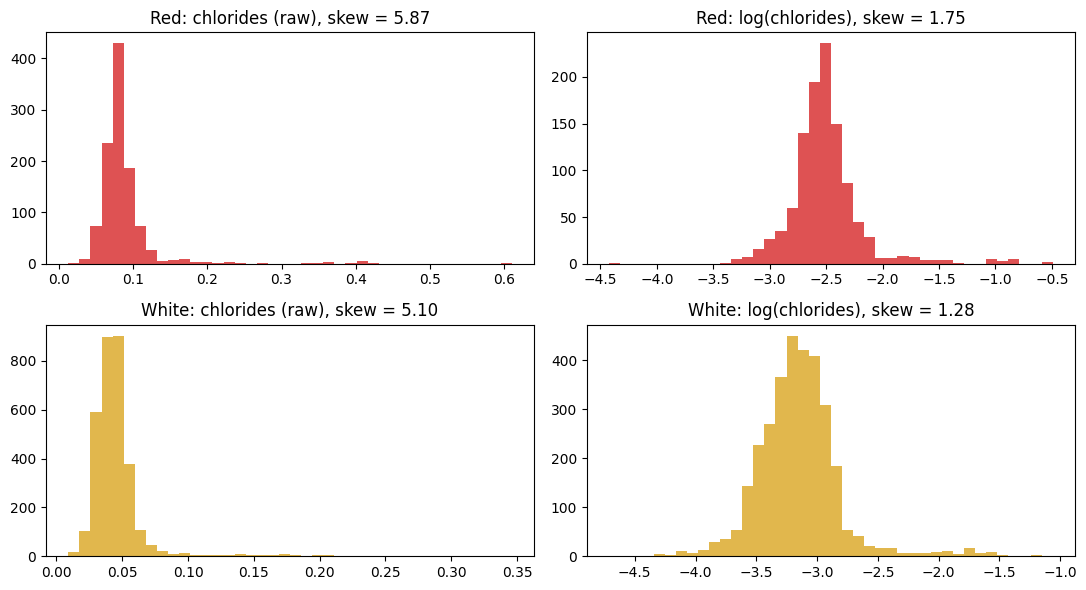

In [5]:
# Most skewed feature (chlorides) before and after
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, (wine, color) in enumerate([("Red", "tab:red"), ("White", "goldenrod")]):
    X_tr = DATASETS[wine][0]
    axes[row, 0].hist(X_tr["chlorides"], bins=40, color=color, alpha=0.8)
    axes[row, 0].set_title(f"{wine}: chlorides (raw), skew = {X_tr['chlorides'].skew():.2f}")
    axes[row, 1].hist(np.log(X_tr["chlorides"]), bins=40, color=color, alpha=0.8)
    axes[row, 1].set_title(f"{wine}: log(chlorides), skew = {np.log(X_tr['chlorides']).skew():.2f}")
plt.tight_layout(); plt.show()

,Dataset,Model,Raw Test MAE,Log Test MAE,Change in Test MAE,Raw CV MAE,Log CV MAE,Raw Test R2,Log Test R2
0,Red,Linear Regression,0.5066,0.5040,-0.0025,0.5160,0.5127,0.3657,0.3725
1,Red,Random Forest,0.4846,0.4839,-0.0007,0.4905,0.4907,0.4054,0.4078
2,Red,KNN,0.5092,0.5111,0.0018,0.5158,0.5132,0.3406,0.3337
3,Red,MLP,0.5044,0.4885,-0.0159,0.5423,0.5378,0.3432,0.3723
4,White,Linear Regression,0.5867,0.5784,-0.0083,0.5776,0.5706,0.2703,0.3027
5,White,Random Forest,0.5426,0.5425,-0.0002,0.5414,0.5411,0.3850,0.3852
6,White,KNN,0.5563,0.5481,-0.0082,0.5536,0.5521,0.3438,0.3602
7,White,MLP,0.5700,0.5668,-0.0032,0.5683,0.5636,0.3304,0.3441


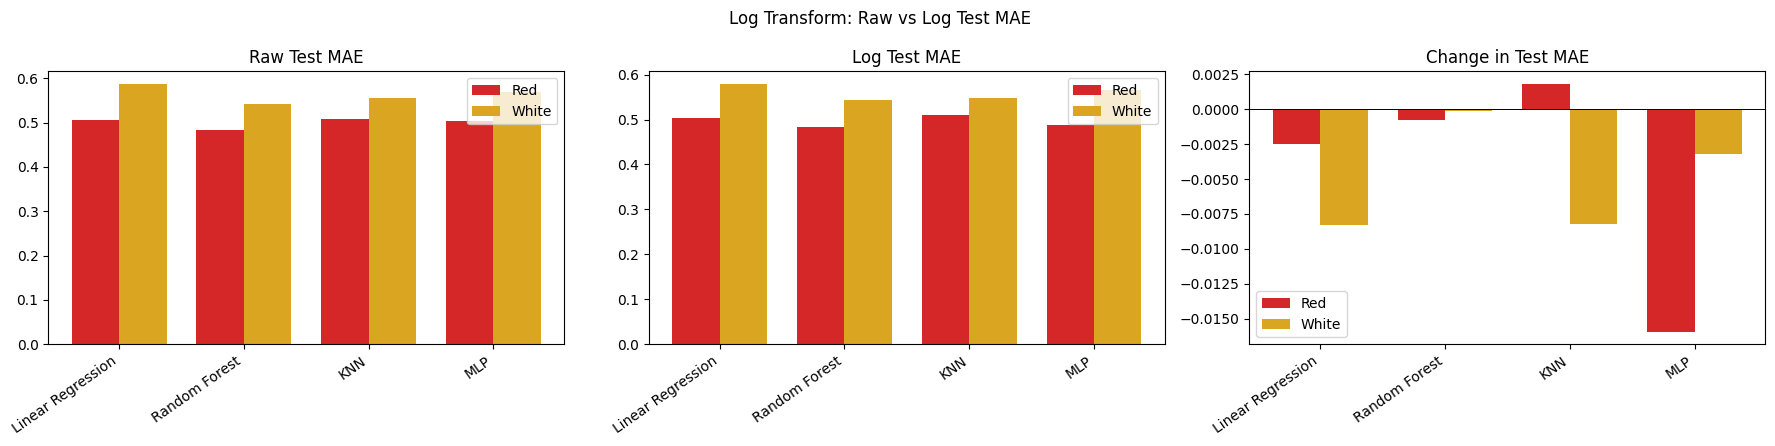

In [6]:
# Raw inputs vs log-transformed inputs, four models, both wines
def with_log(model, functions):
    """Prepend the log step for the chosen columns; every other column passes through unchanged, same order."""
    log_step = FunctionTransformer(log_transform, kw_args={"functions": functions})
    return Pipeline([("log", log_step), ("model", model)])

log_rows = []
for wine, (X_tr, X_te, y_tr, y_te) in DATASETS.items():
    for name, model in make_models(wine).items():
        raw = baseline_df[(baseline_df.Dataset == wine) & (baseline_df.Model == name)].iloc[0]
        log = evaluate(with_log(model, log_functions[wine]), X_tr, y_tr, X_te, y_te)
        log_rows.append({"Dataset": wine, "Model": name,
                         "Raw Test MAE": raw["Test MAE"], "Log Test MAE": log["Test MAE"],
                         "Change in Test MAE": log["Test MAE"] - raw["Test MAE"],
                         "Raw CV MAE": raw["CV MAE"], "Log CV MAE": log["CV MAE"],
                         "Raw Test R2": raw["Test R2"], "Log Test R2": log["Test R2"]})
log_df = pd.DataFrame(log_rows)
show_red_white("Log Transform: Raw vs Log Test MAE", log_df, "Model", ["Raw Test MAE", "Log Test MAE", "Change in Test MAE"])

## 11.3 Fewer features vs all 11

Section 8.4 ranked the 11 features with `SelectKBest(f_regression)` — a univariate test of how strongly each feature is related to quality — and trained Random Forest on the top 3, 5, 8 and all 11. Here the **same ranking and the same subsets** are given to all four models, so any difference between models is due to the model, not the features chosen.

The ranking is fitted on the training set only. Fewer features means fewer laboratory measurements per wine, so a small loss in accuracy for a large reduction in features is a practical result.

In [7]:
# Feature ranking (training set only) and the nested subsets, per dataset
FEATURE_COUNTS = [3, 5, 8, 11]
ranked_features = {}
for wine, (X_tr, X_te, y_tr, y_te) in DATASETS.items():
    selector = SelectKBest(score_func=f_regression, k="all").fit(X_tr, y_tr)
    ranking = pd.Series(selector.scores_, index=X_tr.columns).sort_values(ascending=False)
    ranked_features[wine] = ranking.index.tolist()
    print(f"\n{wine} — features ranked by F-score (most informative first):")
    display(ranking.round(1).to_frame("F-score").T)
    for k in FEATURE_COUNTS[:-1]:
        print(f"  top {k}: {ranked_features[wine][:k]}")


Red — features ranked by F-score (most informative first):


,alcohol,volatile acidity,sulphates,citric acid,density,total sulfur dioxide,chlorides,fixed acidity,pH,free sulfur dioxide,residual sugar
F-score,311.8,203.1,79.4,68.5,38.2,30.5,17.1,15.7,3.3,1.1,0.2


  top 3: ['alcohol', 'volatile acidity', 'sulphates']
  top 5: ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'density']
  top 8: ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'density', 'total sulfur dioxide', 'chlorides', 'fixed acidity']

White — features ranked by F-score (most informative first):


,alcohol,density,chlorides,volatile acidity,total sulfur dioxide,pH,fixed acidity,residual sugar,sulphates,free sulfur dioxide,citric acid
F-score,889.5,443.1,151.3,120.8,112.8,53.4,51.6,45.7,8.3,0.5,0.1


  top 3: ['alcohol', 'density', 'chlorides']
  top 5: ['alcohol', 'density', 'chlorides', 'volatile acidity', 'total sulfur dioxide']
  top 8: ['alcohol', 'density', 'chlorides', 'volatile acidity', 'total sulfur dioxide', 'pH', 'fixed acidity', 'residual sugar']


Model             Linear Regression  Random Forest     KNN     MLP
Dataset Features                                                  
Red     3                    0.5161         0.5291  0.5379  0.5121
        5                    0.5165         0.5143  0.5165  0.5250
        8                    0.5067         0.4898  0.5055  0.4939
        11                   0.5066         0.4846  0.5092  0.5044
White   3                    0.6249         0.6458  0.6525  0.6451
        5                    0.5984         0.5753  0.5759  0.5791
        8                    0.5936         0.5531  0.5692  0.5655
        11                   0.5867         0.5426  0.5563  0.5700

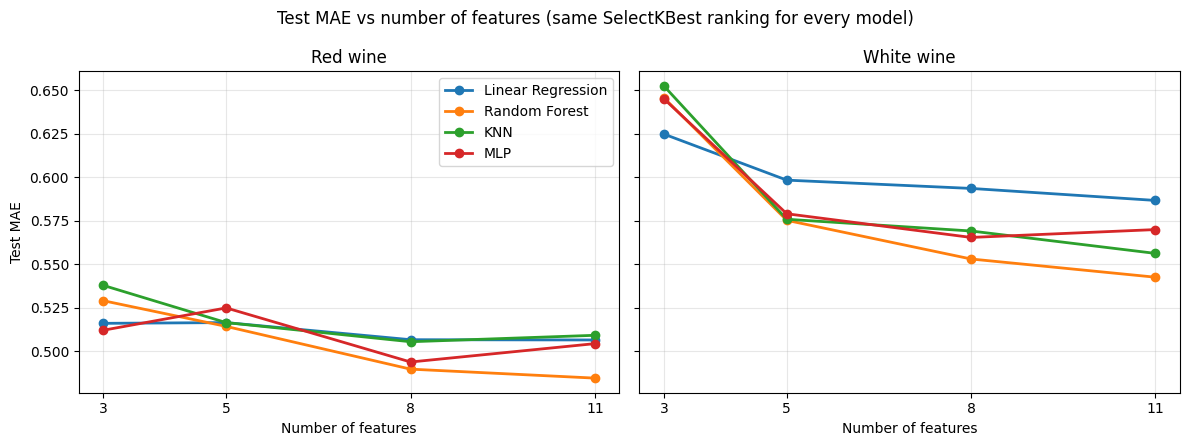

In [8]:
# Top 3 / 5 / 8 / all 11 features, four models, both wines
subset_rows = []
for wine, (X_tr, X_te, y_tr, y_te) in DATASETS.items():
    for k in FEATURE_COUNTS:
        top_k = set(ranked_features[wine][:k])
        cols = [c for c in X_tr.columns if c in top_k]   # keep original column order
        for name, model in make_models(wine).items():
            res = evaluate(model, X_tr[cols], y_tr, X_te[cols], y_te)
            subset_rows.append({"Dataset": wine, "Features": k, "Model": name, **res})
subset_df = pd.DataFrame(subset_rows)

# Table: one row per feature count, one column per model (Test MAE), red and white
subset_table = subset_df.pivot_table(index=["Dataset", "Features"], columns="Model", values="Test MAE")[MODEL_ORDER]
display(subset_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, wine in zip(axes, DATASETS):
    for name in MODEL_ORDER:
        d = subset_df[(subset_df.Dataset == wine) & (subset_df.Model == name)]
        ax.plot(d["Features"], d["Test MAE"], marker="o", linewidth=2, label=name)
    ax.set_title(f"{wine} wine"); ax.set_xlabel("Number of features"); ax.set_xticks(FEATURE_COUNTS); ax.grid(alpha=0.3)
axes[0].set_ylabel("Test MAE"); axes[0].legend()
fig.suptitle("Test MAE vs number of features (same SelectKBest ranking for every model)")
plt.tight_layout(); plt.show()

,Dataset,Model,Test MAE (11),Test MAE (3),Test MAE increase 11→3,CV MAE (11),CV MAE (3),CV MAE increase 11→3
0,Red,Linear Regression,0.5066,0.5161,0.0096,0.5160,0.5225,0.0065
1,Red,Random Forest,0.4846,0.5291,0.0445,0.4905,0.5218,0.0313
2,Red,KNN,0.5092,0.5379,0.0287,0.5158,0.5187,0.0029
3,Red,MLP,0.5044,0.5121,0.0077,0.5423,0.5080,-0.0344
4,White,Linear Regression,0.5867,0.6249,0.0381,0.5776,0.6150,0.0374
5,White,Random Forest,0.5426,0.6458,0.1031,0.5414,0.6208,0.0794
6,White,KNN,0.5563,0.6525,0.0962,0.5536,0.6186,0.0650
7,White,MLP,0.5700,0.6451,0.0751,0.5683,0.6139,0.0457


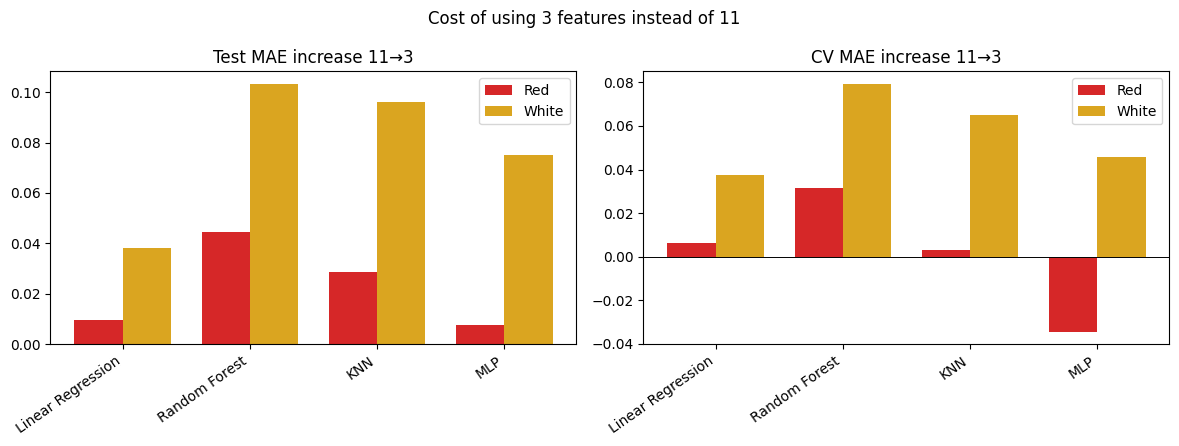

In [9]:
# How much does each model lose when cut from 11 features to 3 (Test MAE and CV MAE)?
loss_rows = []
for wine in DATASETS:
    for name in MODEL_ORDER:
        d = subset_df[(subset_df.Dataset == wine) & (subset_df.Model == name)].set_index("Features")
        loss_rows.append({"Dataset": wine, "Model": name,
                          "Test MAE (11)": d.loc[11, "Test MAE"], "Test MAE (3)": d.loc[3, "Test MAE"],
                          "Test MAE increase 11→3": d.loc[3, "Test MAE"] - d.loc[11, "Test MAE"],
                          "CV MAE (11)": d.loc[11, "CV MAE"], "CV MAE (3)": d.loc[3, "CV MAE"],
                          "CV MAE increase 11→3": d.loc[3, "CV MAE"] - d.loc[11, "CV MAE"]})
loss_df = pd.DataFrame(loss_rows)
show_red_white("Cost of using 3 features instead of 11", loss_df, "Model", ["Test MAE increase 11→3", "CV MAE increase 11→3"])

## 11.4 Summary of Findings

**Log transform (11.2).**
- Five red features and four white features had training-set skewness above 1 and were log-transformed (chlorides was the most extreme: skew 5.9 → 1.8 red, 5.1 → 1.3 white). `log1p` was needed only for white citric acid, which contains zeros.
- **Linear Regression gained the most**, and consistently: test MAE 0.507 → 0.504 (red) and 0.587 → 0.578 (white), with CV MAE moving the same way (0.516 → 0.513; 0.578 → 0.571) and white test R² rising from 0.270 to 0.303. This is the expected effect — least squares is the model most disturbed by a few extreme input values.
- **Random Forest did not change** (−0.0007 red, −0.0002 white). Trees split on thresholds and `log` keeps the order of values, so the splits are the same; the tiny difference is only because scikit-learn places each threshold midway between two training values, and that midpoint moves slightly under `log`.
- **KNN and MLP changed by less than 0.02 MAE in either direction** (KNN +0.002 red / −0.008 white; MLP −0.016 red / −0.003 white). Their `StandardScaler` already handles most of the scale problem, and single-split MLP differences of this size are within run-to-run noise.
- No change in the ranking: Random Forest remains the best model on both wines. The log transform is a small, free improvement for Linear Regression and is harmless elsewhere.

**Fewer features vs all 11 (11.3).**
- The F-score ranking puts **alcohol first for both wines**, followed by volatile acidity and sulphates (red) or density and chlorides (white) — the same features that led the correlation analysis in Section 1 and the importance analysis in Section 10.
- **8 features are as good as 11 for every model** (all differences ≤ 0.013 MAE; KNN and MLP on red were marginally *better* with 8). The three lowest-ranked features (free sulfur dioxide, residual sugar, pH for red; sulphates, free sulfur dioxide, citric acid for white) can be dropped at no cost.
- **Going down to 3 features is cheap for red but expensive for white.** Red: +0.01 (LR), +0.03 (KNN), +0.04 (RF) and ≈0 for MLP (its CV MAE was even lower with 3 features, 0.508 vs 0.542, suggesting the small red training set over-fits with more inputs). White: +0.04 (LR) to +0.10 (RF). White quality depends on a broader mix of chemistry, so it cannot be summarised by three measurements.
- **The flexible models lose the most when features are removed** (RF, KNN), Linear Regression the least. RF uses the weaker features in combination with the strong ones; a linear model cannot exploit such interactions, so it had less to lose.
- Practical reading: for red wine, alcohol + volatile acidity + sulphates recover almost all of the achievable accuracy; for white wine at least 8 measurements are needed to stay within 0.01 MAE of the full model.

**Limitations.** One holdout split; the MLP is a single random initialisation (its test numbers move by ~0.01–0.02 between seeds, which is why CV MAE is shown alongside). The feature ranking is univariate, so it cannot detect a feature that only matters in combination with another.